Analysis for Experiments 3 & 4 (Shreya)

E3: How does range-query cost depend on how much of the data the range covers?	
E4: How does prefix-search cost depend on prefix length?	track_name; prefix lengths 1 through 5

In [1]:
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import seaborn as sns

RESULTS = Path("..") / "results" / "timings.csv"
df = pd.read_csv(RESULTS)

# Per-operation cost: every row is a batch of n_ops operations.
df["us_per_op"] = df["total_ns"] / df["n_ops"] / 1_000 # The microseconds one operation took
for counter in ["comparisons", "nodes_visited", "rotations", "splits", "resizes"]:
    df[f"{counter}_per_op"] = df[counter] / df["n_ops"]

df[["experiment", "index_type", "operation", "operation_param", "us_per_op",
    "comparisons_per_op", "nodes_visited_per_op"]].head()

,experiment,index_type,operation,operation_param,us_per_op,comparisons_per_op,nodes_visited_per_op
0,CORE,unsorted_list,build,NaN,0.122900,0.0,0.0
1,CORE,unsorted_list,build,NaN,0.111384,0.0,0.0
2,CORE,unsorted_list,point_hit,NaN,3924.546877,114000.0,0.0
3,CORE,unsorted_list,point_miss,NaN,3811.619044,114000.0,0.0
4,CORE,unsorted_list,range,0.01,3680.383540,114000.0,0.0


In [2]:
mine = df[df["machine_id"] == "shreya-mbp"]

BEFORE = "e7b23fd"   # original code (B+ tree fix only)
AFTER  = "698521b"   # all fixes

#both versions
e3_all = mine[mine["experiment"] == "E3_range_tempo"].copy()
e4_all = mine[mine["experiment"] == "E4_prefix_track_name"].copy()

#uses only post-fix rows
e3 = e3_all[e3_all["code_version"] == AFTER]
e4 = e4_all[e4_all["code_version"] == AFTER]

print("post-fix E3 rows:", len(e3), "| post-fix E4 rows:", len(e4))

post-fix E3 rows: 210 | post-fix E4 rows: 175


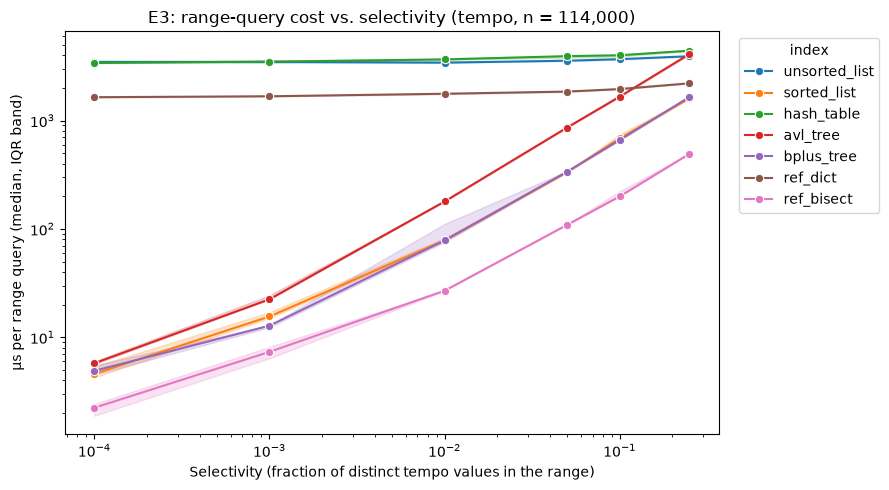

In [3]:
plt.figure(figsize=(9, 5))
sns.lineplot(
    data=e3, x="operation_param", y="us_per_op", hue="index_type",
    estimator="median", errorbar=("pi", 50), marker="o",
)
plt.xscale("log")
plt.yscale("log")
plt.xlabel("Selectivity (fraction of distinct tempo values in the range)")
plt.ylabel("µs per range query (median, IQR band)")
plt.title("E3: range-query cost vs. selectivity (tempo, n = 114,000)")
plt.legend(title="index", bbox_to_anchor=(1.02, 1), loc="upper left")
plt.tight_layout()
plt.savefig("e3_range_postfix.png", dpi=150)
plt.show()

In [4]:
rows = []
for idx, g in e3.groupby("index_type"):
    # median time per query at each selectivity
    med = g.groupby("operation_param")["us_per_op"].median()

    # slope across all 6 selectivities
    slope_all, _ = np.polyfit(np.log10(med.index), np.log10(med.values), 1)

    # slope for the larger ranges only (0.01 and up)
    big = med[med.index >= 0.01]
    slope_big, _ = np.polyfit(np.log10(big.index), np.log10(big.values), 1)

    rows.append({"index": idx,
                 "slope_all": round(slope_all, 2),
                 "slope_0.01_and_up": round(slope_big, 2)})

e3_slopes = pd.DataFrame(rows).sort_values("slope_all")
e3_slopes

,index,slope_all,slope_0.01_and_up
6,unsorted_list,0.01,0.04
2,hash_table,0.03,0.05
4,ref_dict,0.03,0.07
3,ref_bisect,0.68,0.90
5,sorted_list,0.75,0.94
1,bplus_tree,0.76,0.94
0,avl_tree,0.86,0.97


In [5]:
counters = (
    e3.groupby(["index_type", "operation_param"])[["comparisons_per_op", "nodes_visited_per_op", "us_per_op"]]
      .median()
      .round(1)
      .unstack("operation_param")
)
counters

comparisons_per_op                                          \
operation_param             0.0001    0.0010    0.0100    0.0500    0.1000   
index_type                                                                   
avl_tree                      19.0      60.0     470.9    2296.5    4578.3   
bplus_tree                    28.5      69.6     480.6    2306.5    4588.3   
hash_table                 45653.0   45653.0   45653.0   45653.0   45653.0   
ref_bisect                     NaN       NaN       NaN       NaN       NaN   
ref_dict                       NaN       NaN       NaN       NaN       NaN   
sorted_list                   21.5      62.5     473.5    2299.5    4581.6   
unsorted_list             114000.0  114000.0  114000.0  114000.0  114000.0   

                          nodes_visited_per_op                             \
operation_param    0.2500               0.0001   0.0010   0.0100   0.0500   
index_type                                                                  
avl_tree          11426.0                 19.0     60.0    470.9   2296.5   
bplus_tree        11436.5                  4.2      6.1     25.0    109.0   
hash_table        45653.0              65536.0  65536.0  65536.0  65536.0   
ref_bisect            NaN                  NaN      NaN      NaN      NaN   
ref_dict              NaN                  NaN      NaN      NaN      NaN   
sorted_list       11429.6                  0.0      0.0      0.0      0.0   
unsorted_list    114000.0                  0.0      0.0      0.0      0.0   

                                  us_per_op                                  \
operation_param   0.1000   0.2500    0.0001  0.0010  0.0100  0.0500  0.1000   
index_type                                                                    
avl_tree          4578.3  11426.0       5.8    22.4   179.1   860.0  1661.5   
bplus_tree         214.0    529.0       4.9    12.8    78.3   336.9   661.3   
hash_table       65536.0  65536.0    3394.3  3495.8  3662.1  3927.2  4001.7   
ref_bisect           NaN      NaN       2.2     7.3    26.9   108.8   199.3   
ref_dict             NaN      NaN    1641.4  1673.5  1766.5  1848.9  1950.9   
sorted_list          0.0      0.0       4.6    15.6    78.4   332.4   684.8   
unsorted_list        0.0      0.0    3460.3  3480.4  3420.3  3562.7  3682.9   

                         
operation_param  0.2500  
index_type               
avl_tree         4100.5  
bplus_tree       1648.2  
hash_table       4405.2  
ref_bisect        492.7  
ref_dict         2203.4  
sorted_list      1599.0  
unsorted_list    3919.6

In [6]:
main_only = e3[~e3["index_type"].str.startswith("ref_")]   # leave out the C references
med = main_only.groupby(["operation_param", "index_type"])["us_per_op"].median().unstack()

best = pd.DataFrame({
    "fastest": med.idxmin(axis=1),
    "µs": med.min(axis=1).round(1),
    "runner_up": med.apply(lambda r: r.nsmallest(2).index[1], axis=1),
})
best

,fastest,µs,runner_up
operation_param,,,
0.0001,sorted_list,4.6,bplus_tree
0.0010,bplus_tree,12.8,sorted_list
0.0100,bplus_tree,78.3,sorted_list
0.0500,sorted_list,332.4,bplus_tree
0.1000,bplus_tree,661.3,sorted_list
0.2500,sorted_list,1599.0,bplus_tree


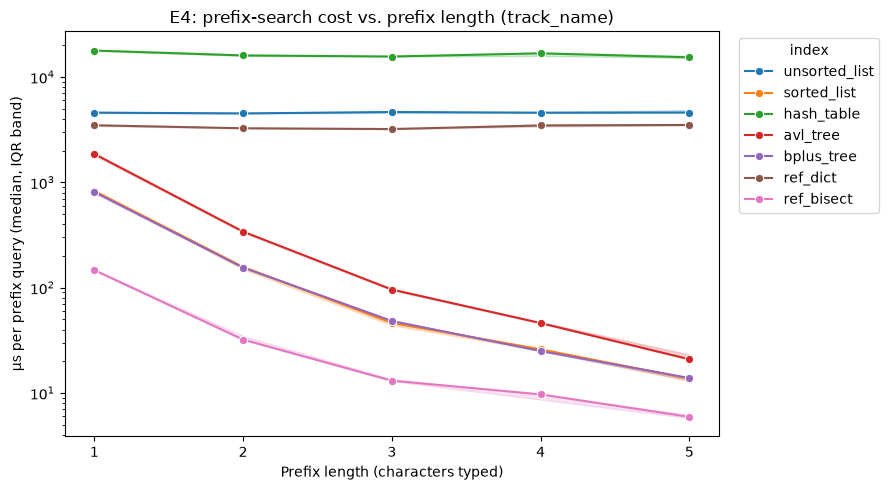

In [7]:
plt.figure(figsize=(9, 5))
sns.lineplot(data=e4, x="operation_param", y="us_per_op", hue="index_type",
             estimator="median", errorbar=("pi", 50), marker="o")
plt.yscale("log")
plt.xticks([1, 2, 3, 4, 5])
plt.xlabel("Prefix length (characters typed)")
plt.ylabel("µs per prefix query (median, IQR band)")
plt.title("E4: prefix-search cost vs. prefix length (track_name)")
plt.legend(title="index", bbox_to_anchor=(1.02, 1), loc="upper left")
plt.tight_layout()
plt.savefig("e4_prefix_postfix.png", dpi=150)
plt.show()

In [8]:
rows = []
for idx, g in e4.groupby("index_type"):
    m = g.groupby("operation_param")["us_per_op"].median()
    slope, _ = np.polyfit(m.index, np.log10(m.values), 1)
    rows.append({"index": idx,
                 "log10_slope_per_char": round(slope, 2),
                 "speedup_per_extra_char": round(10 ** -slope, 1)})
pd.DataFrame(rows).sort_values("log10_slope_per_char")

,index,log10_slope_per_char,speedup_per_extra_char
0,avl_tree,-0.48,3.0
1,bplus_tree,-0.43,2.7
5,sorted_list,-0.43,2.7
3,ref_bisect,-0.33,2.1
2,hash_table,-0.01,1.0
4,ref_dict,0.00,1.0
6,unsorted_list,0.00,1.0


In [9]:
(e4.groupby(["index_type", "operation_param"])[["comparisons_per_op", "nodes_visited_per_op", "us_per_op"]]
   .median().round(1).unstack("operation_param"))

comparisons_per_op                                          \
operation_param                1.0       2.0       3.0       4.0       5.0   
index_type                                                                   
avl_tree                    3659.7     642.1     183.7      91.2      39.3   
bplus_tree                  3669.8     648.8     192.1      99.2      47.8   
hash_table                 72396.0   72396.0   72396.0   72396.0   72396.0   
ref_bisect                     NaN       NaN       NaN       NaN       NaN   
ref_dict                       NaN       NaN       NaN       NaN       NaN   
sorted_list                 3660.5     642.6     184.6      92.0      40.2   
unsorted_list             113999.0  113999.0  113999.0  113999.0  113999.0   

                nodes_visited_per_op                                          \
operation_param                  1.0       2.0       3.0       4.0       5.0   
index_type                                                                     
avl_tree                      3659.7     642.1     183.7      91.2      39.3   
bplus_tree                     171.6      32.7      11.8       7.5       5.1   
hash_table                  131072.0  131072.0  131072.0  131072.0  131072.0   
ref_bisect                       NaN       NaN       NaN       NaN       NaN   
ref_dict                         NaN       NaN       NaN       NaN       NaN   
sorted_list                      0.0       0.0       0.0       0.0       0.0   
unsorted_list                    0.0       0.0       0.0       0.0       0.0   

                us_per_op                                      
operation_param       1.0      2.0      3.0      4.0      5.0  
index_type                                                     
avl_tree           1861.7    340.6     96.0     46.1     20.9  
bplus_tree          809.0    155.2     48.3     25.0     13.9  
hash_table        17826.4  16026.1  15658.5  16792.8  15383.1  
ref_bisect          146.7     32.2     13.1      9.7      5.9  
ref_dict           3485.3   3261.1   3207.4   3467.7   3506.7  
sorted_list         827.8    157.3     46.3     26.0     13.7  
unsorted_list      4590.5   4513.8   4652.2   4581.7   4603.0

In [10]:
def ratio(data, slow, fast):
    m = data.groupby(["operation_param", "index_type"])["us_per_op"].median().unstack()
    return (m[slow] / m[fast]).round(2)

pd.DataFrame({
    "sorted_list / ref_bisect":   ratio(e3, "sorted_list", "ref_bisect"),
    "avl_tree / bplus_tree":      ratio(e3, "avl_tree", "bplus_tree"),
    "hash_table / unsorted_list": ratio(e3, "hash_table", "unsorted_list"),
})

,sorted_list / ref_bisect,avl_tree / bplus_tree,hash_table / unsorted_list
operation_param,,,
0.0001,2.06,1.17,0.98
0.0010,2.12,1.75,1.00
0.0100,2.92,2.29,1.07
0.0500,3.05,2.55,1.10
0.1000,3.44,2.51,1.09
0.2500,3.25,2.49,1.12


In [11]:
#before and after comparison
def before_after(data):
    t = (data.groupby(["index_type", "operation_param", "code_version"])["us_per_op"]
             .median().unstack("code_version"))
    t = t[[BEFORE, AFTER]].rename(columns={BEFORE: "before_us", AFTER: "after_us"})
    t["after/before"] = (t["after_us"] / t["before_us"]).round(2)
    return t.round(1)

print("E3 range"); display(before_after(e3_all))
print("E4 prefix"); display(before_after(e4_all))

E3 range


code_version                   before_us  after_us  after/before
index_type    operation_param                                   
avl_tree      0.0001                 7.3       5.8           0.8
              0.0010                25.9      22.4           0.9
              0.0100               177.6     179.1           1.0
              0.0500               826.1     860.0           1.0
              0.1000              1639.4    1661.5           1.0
              0.2500              4045.8    4100.5           1.0
bplus_tree    0.0001                 5.0       4.9           1.0
              0.0010                12.4      12.8           1.0
              0.0100                77.0      78.3           1.0
              0.0500               340.4     336.9           1.0
              0.1000               668.0     661.3           1.0
              0.2500              1669.2    1648.2           1.0
hash_table    0.0001              6674.8    3394.3           0.5
              0.0010              4511.6    3495.8           0.8
              0.0100              4942.0    3662.1           0.7
              0.0500              5260.9    3927.2           0.8
              0.1000              5623.4    4001.7           0.7
              0.2500              6414.3    4405.2           0.7
ref_bisect    0.0001                 1.9       2.2           1.2
              0.0010                 7.2       7.3           1.0
              0.0100                27.8      26.9           1.0
              0.0500               103.1     108.8           1.1
              0.1000               197.0     199.3           1.0
              0.2500               491.2     492.7           1.0
ref_dict      0.0001              1446.9    1641.4           1.1
              0.0010              1476.2    1673.5           1.1
              0.0100              1521.5    1766.5           1.2
              0.0500              1617.6    1848.9           1.1
              0.1000              1727.8    1950.9           1.1
              0.2500              2067.6    2203.4           1.1
sorted_list   0.0001                 4.6       4.6           1.0
              0.0010                16.8      15.6           0.9
              0.0100                95.4      78.4           0.8
              0.0500               333.8     332.4           1.0
              0.1000               683.5     684.8           1.0
              0.2500              2032.1    1599.0           0.8
unsorted_list 0.0001              3442.9    3460.3           1.0
              0.0010              3497.5    3480.4           1.0
              0.0100              3678.2    3420.3           0.9
              0.0500              3799.7    3562.7           0.9
              0.1000              3756.2    3682.9           1.0
              0.2500              3904.1    3919.6           1.0

E4 prefix


code_version                   before_us  after_us  after/before
index_type    operation_param                                   
avl_tree      1.0                 1801.7    1861.7           1.0
              2.0                  343.8     340.6           1.0
              3.0                   94.9      96.0           1.0
              4.0                   48.7      46.1           1.0
              5.0                   22.8      20.9           0.9
bplus_tree    1.0                  781.4     809.0           1.0
              2.0                  156.1     155.2           1.0
              3.0                   44.7      48.3           1.1
              4.0                   24.0      25.0           1.0
              5.0                   12.8      13.9           1.1
hash_table    1.0                18692.8   17826.4           1.0
              2.0                17886.5   16026.1           0.9
              3.0                16528.4   15658.5           1.0
              4.0                16173.7   16792.8           1.0
              5.0                16811.5   15383.1           0.9
ref_bisect    1.0                  152.3     146.7           1.0
              2.0                   35.4      32.2           0.9
              3.0                   12.7      13.1           1.0
              4.0                    7.9       9.7           1.2
              5.0                    5.9       5.9           1.0
ref_dict      1.0                 3435.8    3485.3           1.0
              2.0                 3312.0    3261.1           1.0
              3.0                 3218.8    3207.4           1.0
              4.0                 3219.4    3467.7           1.1
              5.0                 3310.9    3506.7           1.1
sorted_list   1.0                  761.1     827.8           1.1
              2.0                  172.9     157.3           0.9
              3.0                   45.5      46.3           1.0
              4.0                   25.3      26.0           1.0
              5.0                   12.8      13.7           1.1
unsorted_list 1.0                 4559.7    4590.5           1.0
              2.0                 4519.1    4513.8           1.0
              3.0                 4653.7    4652.2           1.0
              4.0                 4595.4    4581.7           1.0
              5.0                 4700.2    4603.0           1.0